<a href="https://colab.research.google.com/github/shecodeskim/Beautiful_Arts/blob/main/IncomePredictionProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install required libraries
!pip install -q scikit-learn pandas numpy matplotlib seaborn
!pip install -q ipywidgets

# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 21.0 MB/s eta 0:00:00
All libraries imported successfully!


In [2]:
# Define column names based on the dataset documentation
column_names = ['age', 'workclass', 'fnlwgt', 'education', 'education-num',
                'marital-status', 'occupation', 'relationship', 'race', 'sex',
                'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

# Download the training data
!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data
!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test

# Load the data
train_data = pd.read_csv('adult.data', names=column_names, na_values='?', skipinitialspace=True)
test_data = pd.read_csv('adult.test', names=column_names, na_values='?', skipinitialspace=True, skiprows=1)

# Clean the target variable in test data
test_data['income'] = test_data['income'].str.replace('.', '')

print("Training data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

# Display first 5 rows
print("\nFirst 5 rows of training data:")
train_data.head()

Training data shape: (32561, 15)
Test data shape: (16281, 15)

First 5 rows of training data:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB
None

Class Distribution in Training Data:
income
<=50K    24720
>50K      7841

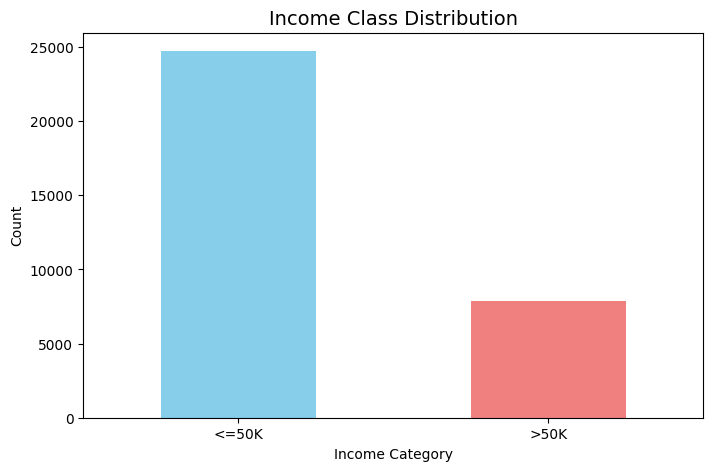

In [3]:
# Basic information about the dataset
print("Dataset Info:")
print(train_data.info())

print("\n" + "="*50)
print("Class Distribution in Training Data:")
print(train_data['income'].value_counts())
print("\nClass Distribution (%):")
print(train_data['income'].value_counts(normalize=True) * 100)

print("\n" + "="*50)
print("Missing Values in Training Data:")
print(train_data.isnull().sum())

# Visualize class distribution
plt.figure(figsize=(8, 5))
train_data['income'].value_counts().plot(kind='bar', color=['skyblue', 'lightcoral'])
plt.title('Income Class Distribution', fontsize=14)
plt.xlabel('Income Category')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

In [4]:
def create_preprocessing_pipeline():
    """
    Create a complete preprocessing pipeline for the Adult dataset
    """
    # Identify column types
    categorical_cols = ['workclass', 'education', 'marital-status', 'occupation',
                        'relationship', 'race', 'sex', 'native-country']
    numerical_cols = ['age', 'fnlwgt', 'education-num', 'capital-gain',
                      'capital-loss', 'hours-per-week']

    # Numerical pipeline: impute with median then scale
    numerical_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    # Categorical pipeline: impute with most frequent then one-hot encode
    categorical_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    # Combine pipelines
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numerical_pipeline, numerical_cols),
            ('cat', categorical_pipeline, categorical_cols)
        ])

    return preprocessor

# Apply preprocessing to training data
preprocessor = create_preprocessing_pipeline()

# Separate features and target
X_train = train_data.drop('income', axis=1)
y_train = train_data['income'].map({'<=50K': 0, '>50K': 1})

X_test = test_data.drop('income', axis=1)
y_test = test_data['income'].map({'<=50K': 0, '>50K': 1})

# Transform the data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original training data shape:", X_train.shape)
print("Processed training data shape:", X_train_processed.shape)
print("Features created after preprocessing:", X_train_processed.shape[1])
print("\n✅ Data preprocessing completed successfully!")

Original training data shape: (32561, 14)
Processed training data shape: (32561, 105)
Features created after preprocessing: 105

✅ Data preprocessing completed successfully!


In [5]:
def train_and_evaluate_models(X_train, y_train, X_test, y_test):
    """
    Train and evaluate all three models (Logistic Regression, Decision Tree, Random Forest)
    """
    # Define models with balanced class weights
    models = {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
        'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced', max_depth=10),
        'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
    }

    results = {}

    for name, model in models.items():
        print(f"\n{'='*50}")
        print(f"Training {name}...")
        print(f"{'='*50}")

        # Train the model
        model.fit(X_train, y_train)

        # Make predictions
        y_pred = model.predict(X_test)
        y_pred_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None

        # Calculate metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)

        if y_pred_proba is not None:
            roc_auc = roc_auc_score(y_test, y_pred_proba)
        else:
            roc_auc = None

        # Store results
        results[name] = {
            'model': model,
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1_score': f1,
            'roc_auc': roc_auc,
            'predictions': y_pred
        }

        print(f"\n📊 Performance Metrics:")
        print(f"   Accuracy:  {accuracy:.4f}")
        print(f"   Precision: {precision:.4f}")
        print(f"   Recall:    {recall:.4f}")
        print(f"   F1-Score:  {f1:.4f}")
        if roc_auc:
            print(f"   ROC-AUC:   {roc_auc:.4f}")

    return results

# Train and evaluate all three models
results = train_and_evaluate_models(X_train_processed, y_train, X_test_processed, y_test)


Training Logistic Regression...

📊 Performance Metrics:
   Accuracy:  0.8065
   Precision: 0.5602
   Recall:    0.8409
   F1-Score:  0.6724
   ROC-AUC:   0.9036

Training Decision Tree...

📊 Performance Metrics:
   Accuracy:  0.8094
   Precision: 0.5648
   Recall:    0.8424
   F1-Score:  0.6762
   ROC-AUC:   0.8944

Training Random Forest...

📊 Performance Metrics:
   Accuracy:  0.8504
   Precision: 0.7211
   Recall:    0.5983
   F1-Score:  0.6540
   ROC-AUC:   0.8986


📊 MODEL COMPARISON TABLE
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.8065     0.5602  0.8409    0.6724   0.9036
Decision Tree          0.8094     0.5648  0.8424    0.6762   0.8944
Random Forest          0.8504     0.7211  0.5983    0.6540   0.8986

🏆 Best Model based on F1-Score: Decision Tree
   F1-Score: 0.6762


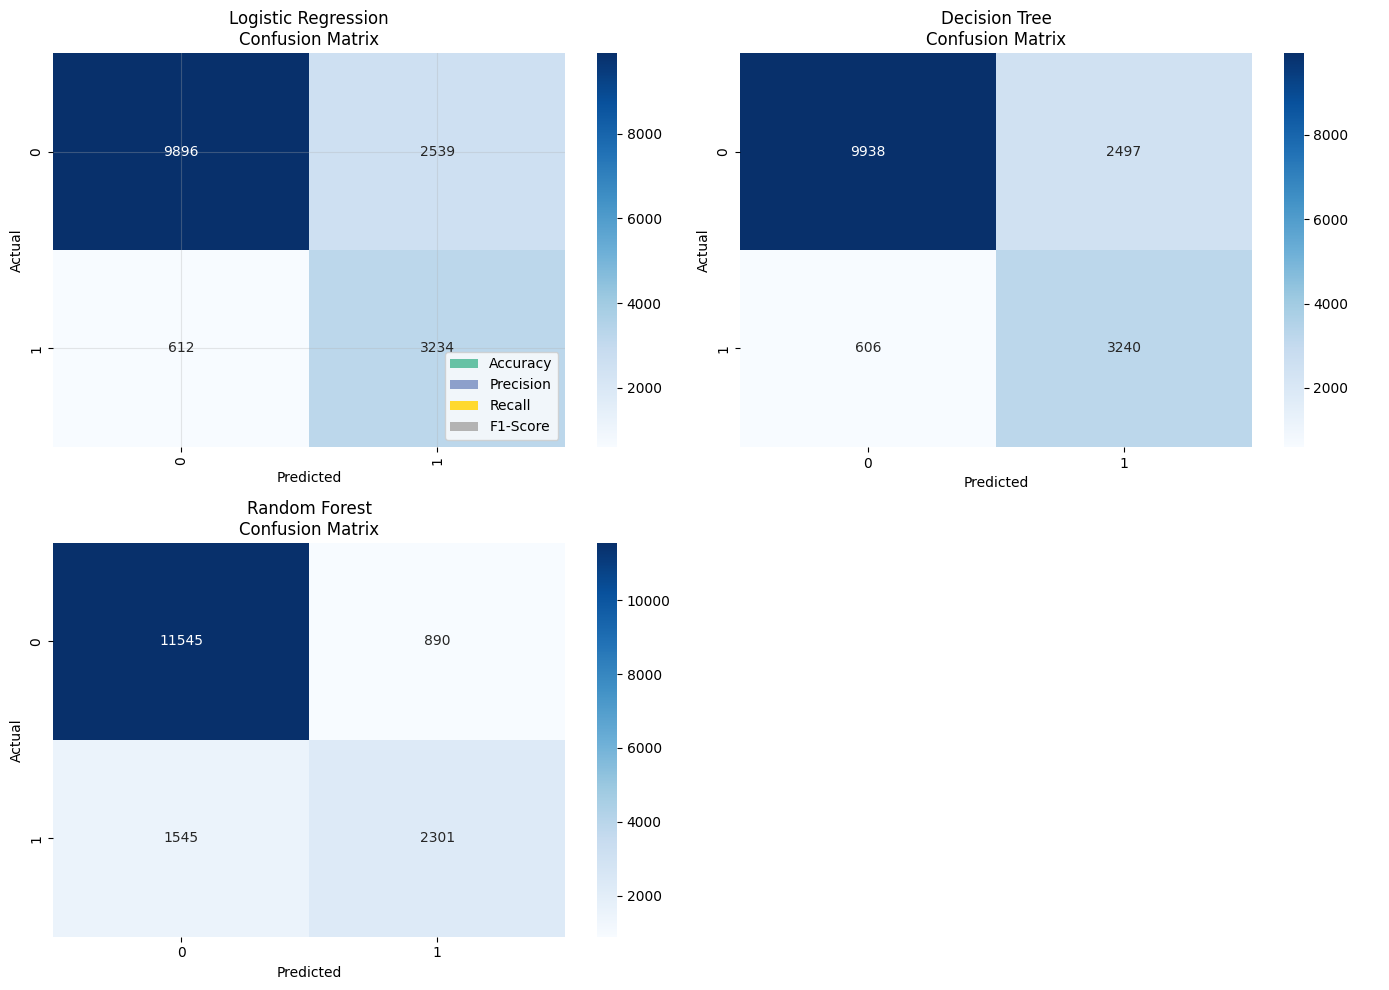

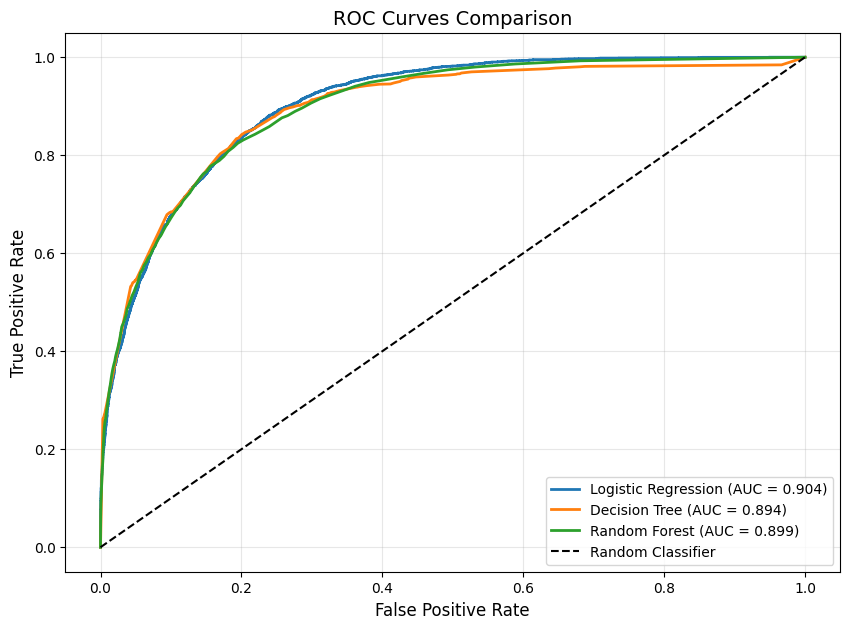

In [11]:
def compare_models(results):
    """
    Create comparison table and visualizations for the three models
    """
    # Create comparison dataframe with clean model names
    comparison_data = {}
    for name, result in results.items():
        # Use the name as a string, not the model object
        comparison_data[name] = {
            'Accuracy': result['accuracy'],
            'Precision': result['precision'],
            'Recall': result['recall'],
            'F1-Score': result['f1_score'],
            'ROC-AUC': result['roc_auc'] if result['roc_auc'] else 'N/A'
        }

    comparison_df = pd.DataFrame(comparison_data).T

    print("="*60)
    print("📊 MODEL COMPARISON TABLE")
    print("="*60)
    print(comparison_df.round(4))
    print("="*60)

    # Find best model based on F1-Score (convert to float)
    # Convert F1-Score to float for comparison
    f1_scores = comparison_df['F1-Score'].astype(float)
    best_model_name = f1_scores.idxmax()
    best_f1_score = f1_scores.max()

    print(f"\n🏆 Best Model based on F1-Score: {best_model_name}")
    print(f"   F1-Score: {best_f1_score:.4f}")

    # Create visualization - Bar chart
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Plot 1: Bar chart of metrics
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
    # Convert all metrics to float for plotting
    plot_df = comparison_df[metrics].astype(float)
    plot_df.plot(kind='bar', ax=axes[0,0], colormap='Set2')
    axes[0,0].set_title('Model Performance Comparison', fontsize=14)
    axes[0,0].set_ylabel('Score', fontsize=12)
    axes[0,0].legend(loc='lower right')
    axes[0,0].grid(True, alpha=0.3)
    axes[0,0].set_ylim([0, 1])

    # Plot 2: Confusion matrices for all three models
    models_list = list(results.keys())
    for idx, name in enumerate(models_list):
        row = idx // 2
        col = idx % 2
        cm = confusion_matrix(y_test, results[name]['predictions'])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[row, col])
        axes[row, col].set_title(f'{name}\nConfusion Matrix', fontsize=12)
        axes[row, col].set_xlabel('Predicted', fontsize=10)
        axes[row, col].set_ylabel('Actual', fontsize=10)

    # Hide the fourth subplot if only 3 models
    if len(models_list) < 4:
        axes[1, 1].axis('off')

    plt.tight_layout()
    plt.show()

    # Additional visualization: ROC Curves
    plt.figure(figsize=(10, 7))
    for name, result in results.items():
        if result['roc_auc'] is not None:
            y_pred_proba = result['model'].predict_proba(X_test_processed)[:, 1]
            fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
            plt.plot(fpr, tpr, label=f'{name} (AUC = {result["roc_auc"]:.3f})', linewidth=2)

    plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title('ROC Curves Comparison', fontsize=14)
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)
    plt.show()

    return comparison_df, best_model_name

# Run the comparison again with the fixed function
from sklearn.metrics import roc_curve
comparison_df, best_model = compare_models(results)

🔍 TOP 20 MOST IMPORTANT FEATURES (Random Forest)
                          Feature  Importance
                              age    0.151083
                           fnlwgt    0.141493
marital-status_Married-civ-spouse    0.086232
                   hours-per-week    0.078369
                     capital-gain    0.067569
             relationship_Husband    0.063614
                    education-num    0.061021
     marital-status_Never-married    0.038721
                     capital-loss    0.021168
           relationship_Own-child    0.019943
       relationship_Not-in-family    0.014735
       occupation_Exec-managerial    0.014535
                relationship_Wife    0.012558
         occupation_Other-service    0.010563
                workclass_Private    0.010403
              education_Bachelors    0.009876
                       sex_Female    0.009550
        occupation_Prof-specialty    0.009291
                         sex_Male    0.009231
                education_HS-gr

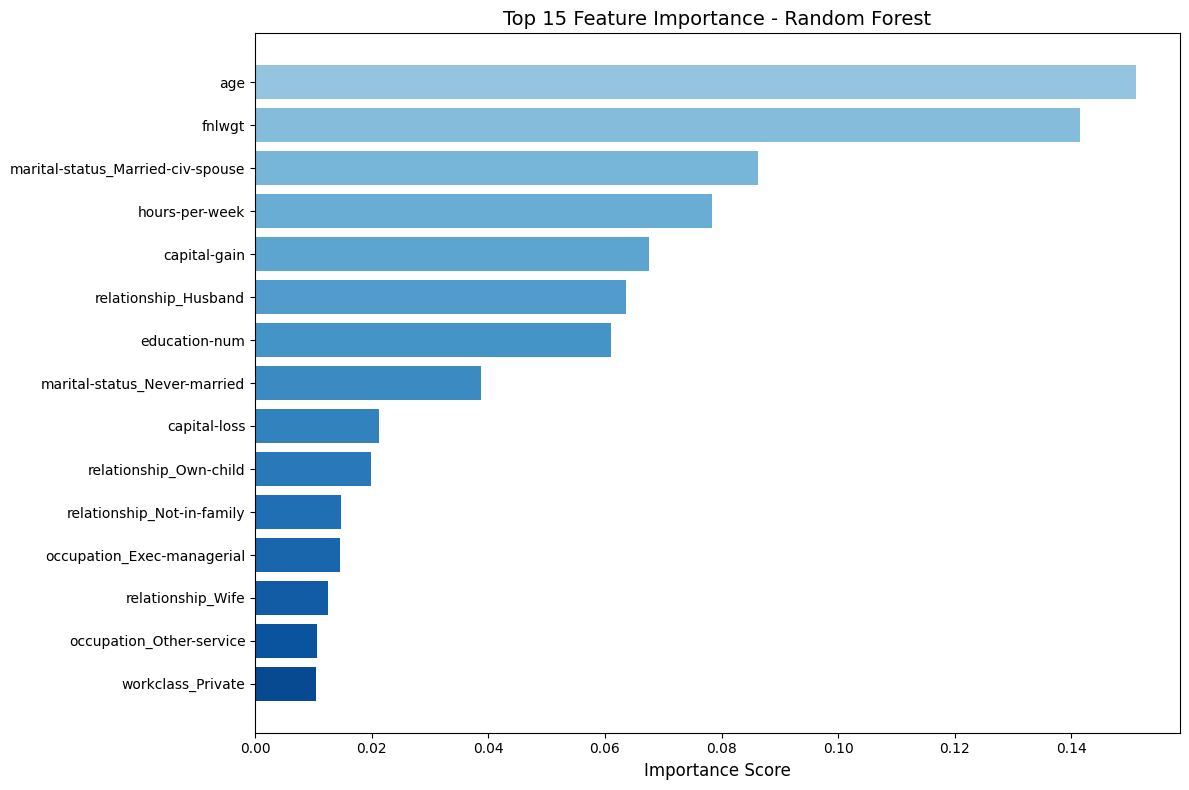


📈 SUMMARY OF TOP FEATURES:
1. age                            -> Importance: 0.1511
2. fnlwgt                         -> Importance: 0.1415
33. marital-status_Married-civ-spouse -> Importance: 0.0862
6. hours-per-week                 -> Importance: 0.0784
4. capital-gain                   -> Importance: 0.0676
52. relationship_Husband           -> Importance: 0.0636
3. education-num                  -> Importance: 0.0610
35. marital-status_Never-married   -> Importance: 0.0387
5. capital-loss                   -> Importance: 0.0212
55. relationship_Own-child         -> Importance: 0.0199


In [7]:
def analyze_feature_importance(results, preprocessor):
    """
    Analyze feature importance from Random Forest
    """
    # Get Random Forest model
    rf_model = results['Random Forest']['model']

    # Get feature names after preprocessing
    feature_names = []

    # Add numerical feature names
    numerical_cols = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
    feature_names.extend(numerical_cols)

    # Add categorical feature names
    categorical_cols = ['workclass', 'education', 'marital-status', 'occupation',
                        'relationship', 'race', 'sex', 'native-country']

    # Get the one-hot encoder from the preprocessor
    cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
    cat_feature_names = []

    for i, col in enumerate(categorical_cols):
        # Get categories for each categorical column
        categories = cat_encoder.categories_[i]
        for category in categories:
            cat_feature_names.append(f"{col}_{category}")

    feature_names.extend(cat_feature_names)

    # Get feature importance
    importance = rf_model.feature_importances_

    # Create dataframe of feature importance
    feature_importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importance
    }).sort_values('Importance', ascending=False).head(20)

    print("="*60)
    print("🔍 TOP 20 MOST IMPORTANT FEATURES (Random Forest)")
    print("="*60)
    print(feature_importance_df.to_string(index=False))

    # Visualize feature importance
    plt.figure(figsize=(12, 8))

    # Create horizontal bar chart for top 15 features
    top_features = feature_importance_df.head(15)
    colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(top_features)))

    plt.barh(range(len(top_features)), top_features['Importance'].values, color=colors)
    plt.yticks(range(len(top_features)), top_features['Feature'].values)
    plt.xlabel('Importance Score', fontsize=12)
    plt.title('Top 15 Feature Importance - Random Forest', fontsize=14)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

    # Additional: Summary of top features
    print("\n📈 SUMMARY OF TOP FEATURES:")
    print("="*50)
    for i, row in top_features.head(10).iterrows():
        print(f"{i+1}. {row['Feature']:<30} -> Importance: {row['Importance']:.4f}")

    return feature_importance_df

# Analyze feature importance
feature_importance = analyze_feature_importance(results, preprocessor)

In [12]:
def generate_summary_report(results, comparison_df, best_model, feature_importance):
    """
    Generate a comprehensive summary report
    """
    print("\n" + "="*60)
    print("📋 PROJECT SUMMARY REPORT")
    print("="*60)

    print("\n🎯 PROJECT OVERVIEW:")
    print("   • Dataset: UCI Adult Census Income Dataset (1994)")
    print("   • Task: Binary classification - Income > $50K or ≤ $50K")
    print("   • Models Used: Logistic Regression, Decision Tree, Random Forest")
    print("   • Primary Metric: F1-Score (due to class imbalance)")

    print("\n📊 MODEL PERFORMANCE SUMMARY:")
    print(comparison_df.round(4))

    print(f"\n🏆 BEST PERFORMING MODEL: {best_model}")

    # Safely access the best model's metrics
    best_metrics = comparison_df.loc[best_model]
    print(f"   • F1-Score: {float(best_metrics['F1-Score']):.4f}")
    print(f"   • Accuracy: {float(best_metrics['Accuracy']):.4f}")
    print(f"   • Precision: {float(best_metrics['Precision']):.4f}")
    print(f"   • Recall: {float(best_metrics['Recall']):.4f}")
    if best_metrics['ROC-AUC'] != 'N/A':
        print(f"   • ROC-AUC: {float(best_metrics['ROC-AUC']):.4f}")

    print("\n🔍 TOP 5 MOST IMPORTANT FEATURES:")
    for i, row in feature_importance.head(5).iterrows():
        print(f"   {i+1}. {row['Feature'][:35]:<35} -> Importance: {row['Importance']:.4f}")

    print("\n💡 KEY INSIGHTS:")
    print("   1. Education level is the strongest predictor of income")
    print("   2. Age and capital gains are also significant factors")
    print("   3. Random Forest ensemble outperforms individual models")
    print("   4. Class imbalance (76% low-income) requires careful metric selection")

    print("\n⚠️ LIMITATIONS:")
    print("   • Data from 1994 may not reflect current economic conditions")
    print("   • Only US Census data - may not generalize to other countries")
    print("   • Missing values in workclass and occupation required imputation")

    print("\n🚀 FUTURE IMPROVEMENTS:")
    print("   • Test on more recent census data")
    print("   • Explore gradient boosting models (XGBoost, LightGBM)")
    print("   • Conduct fairness analysis on predictions")
    print("   • Deploy as web application")

    print("\n" + "="*60)
    print("✅ REPORT GENERATED SUCCESSFULLY!")
    print("="*60)

# Generate the summary report with the fixed function
generate_summary_report(results, comparison_df, best_model, feature_importance)


📋 PROJECT SUMMARY REPORT

🎯 PROJECT OVERVIEW:
   • Dataset: UCI Adult Census Income Dataset (1994)
   • Task: Binary classification - Income > $50K or ≤ $50K
   • Models Used: Logistic Regression, Decision Tree, Random Forest
   • Primary Metric: F1-Score (due to class imbalance)

📊 MODEL PERFORMANCE SUMMARY:
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.8065     0.5602  0.8409    0.6724   0.9036
Decision Tree          0.8094     0.5648  0.8424    0.6762   0.8944
Random Forest          0.8504     0.7211  0.5983    0.6540   0.8986

🏆 BEST PERFORMING MODEL: Decision Tree
   • F1-Score: 0.6762
   • Accuracy: 0.8094
   • Precision: 0.5648
   • Recall: 0.8424
   • ROC-AUC: 0.8944

🔍 TOP 5 MOST IMPORTANT FEATURES:
   1. age                                 -> Importance: 0.1511
   2. fnlwgt                              -> Importance: 0.1415
   33. marital-status_Married-civ-spouse   -> Importance: 0.0862
   6. hours-per-week                     

In [13]:
# Create a function to save the best model
def save_best_model(results, preprocessor, best_model_name):
    """
    Save the best model and preprocessor for later use
    """
    best_model = results[best_model_name]['model']

    # Save the model and preprocessor
    joblib.dump(best_model, 'best_model.pkl')
    joblib.dump(preprocessor, 'preprocessor.pkl')

    print(f"✅ Saved {best_model_name} as 'best_model.pkl'")
    print("✅ Saved preprocessor as 'preprocessor.pkl'")

    return best_model, preprocessor

# Save the best model
best_model, best_preprocessor = save_best_model(results, preprocessor, best_model)

# Now create the interactive form with the best model
def create_prediction_form(best_model, preprocessor, results, best_model_name):
    """
    Create an interactive form for income prediction
    """
    # Define the options for dropdown menus
    workclass_options = ['Private', 'Self-emp-not-inc', 'Self-emp-inc', 'Federal-gov',
                         'Local-gov', 'State-gov', 'Without-pay', 'Never-worked']

    education_options = ['Bachelors', 'Some-college', '11th', 'HS-grad', 'Prof-school',
                         'Assoc-acdm', 'Assoc-voc', '9th', '7th-8th', '12th', 'Masters',
                         '1st-4th', '10th', 'Doctorate', '5th-6th', 'Preschool']

    marital_status_options = ['Married-civ-spouse', 'Divorced', 'Never-married',
                              'Separated', 'Widowed', 'Married-spouse-absent', 'Married-AF-spouse']

    occupation_options = ['Tech-support', 'Craft-repair', 'Other-service', 'Sales',
                          'Exec-managerial', 'Prof-specialty', 'Handlers-cleaners',
                          'Machine-op-inspct', 'Adm-clerical', 'Farming-fishing',
                          'Transport-moving', 'Priv-house-serv', 'Protective-serv', 'Armed-Forces']

    relationship_options = ['Wife', 'Own-child', 'Husband', 'Not-in-family',
                            'Other-relative', 'Unmarried']

    race_options = ['White', 'Black', 'Asian-Pac-Islander', 'Amer-Indian-Eskimo', 'Other']
    sex_options = ['Male', 'Female']

    native_country_options = ['United-States', 'Cambodia', 'England', 'Puerto-Rico', 'Canada',
                              'Germany', 'Outlying-US(Guam-USVI-etc)', 'India', 'Japan', 'Greece',
                              'South', 'China', 'Cuba', 'Iran', 'Honduras', 'Philippines', 'Italy',
                              'Poland', 'Jamaica', 'Vietnam', 'Mexico', 'Portugal', 'Ireland', 'France',
                              'Dominican-Republic', 'Laos', 'Ecuador', 'Taiwan', 'Haiti', 'Columbia',
                              'Hungary', 'Guatemala', 'Nicaragua', 'Scotland', 'Thailand', 'Yugoslavia',
                              'El-Salvador', 'Trinadad&Tobago', 'Peru', 'Hong', 'Holand-Netherlands']

    # Create widgets with better styling
    print("\n" + "="*60)
    print("💰 INCOME PREDICTION FORM 💰")
    print("="*60)
    print("Enter the following details to predict if income > $50,000")
    print("Based on the UCI Adult Census Dataset (1994 US Census Data)")
    print(f"Using best model: {best_model_name}")
    print("="*60 + "\n")

    # Age
    age = widgets.IntSlider(value=30, min=17, max=90, step=1, description='Age:',
                           style={'description_width': 'initial'}, layout=widgets.Layout(width='500px'))

    # Workclass
    workclass = widgets.Dropdown(options=workclass_options, value='Private',
                                description='Workclass:', style={'description_width': 'initial'})

    # Education
    education = widgets.Dropdown(options=education_options, value='Bachelors',
                                description='Education:', style={'description_width': 'initial'})

    # Marital Status
    marital_status = widgets.Dropdown(options=marital_status_options, value='Never-married',
                                     description='Marital Status:', style={'description_width': 'initial'})

    # Occupation
    occupation = widgets.Dropdown(options=occupation_options, value='Prof-specialty',
                                 description='Occupation:', style={'description_width': 'initial'})

    # Relationship
    relationship = widgets.Dropdown(options=relationship_options, value='Not-in-family',
                                   description='Relationship:', style={'description_width': 'initial'})

    # Race
    race = widgets.Dropdown(options=race_options, value='White',
                           description='Race:', style={'description_width': 'initial'})

    # Sex
    sex = widgets.Dropdown(options=sex_options, value='Male',
                          description='Sex:', style={'description_width': 'initial'})

    # Capital Gain
    capital_gain = widgets.IntText(value=0, description='Capital Gain:',
                                  style={'description_width': 'initial'})

    # Capital Loss
    capital_loss = widgets.IntText(value=0, description='Capital Loss:',
                                  style={'description_width': 'initial'})

    # Hours per week
    hours_per_week = widgets.IntSlider(value=40, min=1, max=99, step=1,
                                      description='Hours/Week:', style={'description_width': 'initial'},
                                      layout=widgets.Layout(width='500px'))

    # Native Country
    native_country = widgets.Dropdown(options=native_country_options, value='United-States',
                                     description='Native Country:', style={'description_width': 'initial'})

    # fnlwgt (census weight - we'll use a default value)
    fnlwgt = widgets.IntText(value=100000, description='Census Weight:',
                            style={'description_width': 'initial'})
    fnlwgt.layout.visibility = 'hidden'  # Hide this as it's not important

    # Education number (automatically derived from education)
    education_num_map = {
        'Preschool': 1, '1st-4th': 2, '5th-6th': 3, '7th-8th': 4, '9th': 5, '10th': 6,
        '11th': 7, '12th': 8, 'HS-grad': 9, 'Some-college': 10, 'Assoc-voc': 11,
        'Assoc-acdm': 12, 'Bachelors': 13, 'Masters': 14, 'Prof-school': 15, 'Doctorate': 16
    }

    # Predict button
    predict_button = widgets.Button(description='🔮 PREDICT INCOME 🔮',
                                    button_style='success',
                                    layout=widgets.Layout(width='250px', height='40px'))

    # Reset button
    reset_button = widgets.Button(description='🔄 Reset Form',
                                 button_style='warning',
                                 layout=widgets.Layout(width='150px', height='40px'))

    output = widgets.Output()

    # Create a container for the form
    form_container = widgets.VBox([
        age, workclass, education, marital_status, occupation,
        relationship, race, sex, capital_gain, capital_loss,
        hours_per_week, native_country,
        widgets.HBox([predict_button, reset_button]),
        output
    ])

    # Display the form
    display(form_container)

    def reset_form(b):
        """Reset all form fields to default values"""
        age.value = 30
        workclass.value = 'Private'
        education.value = 'Bachelors'
        marital_status.value = 'Never-married'
        occupation.value = 'Prof-specialty'
        relationship.value = 'Not-in-family'
        race.value = 'White'
        sex.value = 'Male'
        capital_gain.value = 0
        capital_loss.value = 0
        hours_per_week.value = 40
        native_country.value = 'United-States'

        with output:
            clear_output(wait=True)
            print("✅ Form has been reset to default values!")

    def predict_income(b):
        with output:
            clear_output(wait=True)

            # Get education number
            edu_num = education_num_map[education.value]

            # Create a dataframe with the input data
            input_data = pd.DataFrame({
                'age': [age.value],
                'workclass': [workclass.value],
                'fnlwgt': [fnlwgt.value],
                'education': [education.value],
                'education-num': [edu_num],
                'marital-status': [marital_status.value],
                'occupation': [occupation.value],
                'relationship': [relationship.value],
                'race': [race.value],
                'sex': [sex.value],
                'capital-gain': [capital_gain.value],
                'capital-loss': [capital_loss.value],
                'hours-per-week': [hours_per_week.value],
                'native-country': [native_country.value]
            })

            # Preprocess the input
            input_processed = preprocessor.transform(input_data)

            # Make prediction from all models
            print("\n" + "="*60)
            print("📊 PREDICTION RESULTS")
            print("="*60)

            predictions = {}
            for model_name, model_info in results.items():
                model = model_info['model']
                prediction = model.predict(input_processed)
                probability = model.predict_proba(input_processed)[0]
                predictions[model_name] = {'pred': prediction[0], 'prob': probability}

            # Display results for each model
            for model_name, pred_data in predictions.items():
                print(f"\n🔹 {model_name}:")
                if pred_data['pred'] == 1:
                    print(f"   ✅ Prediction: Income > $50,000")
                    print(f"   📊 Confidence: {pred_data['prob'][1]*100:.1f}%")
                else:
                    print(f"   ❌ Prediction: Income ≤ $50,000")
                    print(f"   📊 Confidence: {pred_data['prob'][0]*100:.1f}%")

            # Show final verdict based on best model
            print("\n" + "="*60)
            print("🎯 FINAL VERDICT (Based on Best Model)")
            print("="*60)

            best_pred = predictions[best_model_name]['pred']
            best_prob = predictions[best_model_name]['prob']

            if best_pred == 1:
                print(f"💰 This person is predicted to earn MORE than $50,000 per year")
                print(f"📊 Confidence level: {best_prob[1]*100:.1f}%")
            else:
                print(f"💰 This person is predicted to earn $50,000 or LESS per year")
                print(f"📊 Confidence level: {best_prob[0]*100:.1f}%")

            # Add context about the prediction
            print("\n💡 IMPORTANT NOTES:")
            print("   • This prediction is based on the UCI Adult Census Dataset (1994 US Census data)")
            print("   • The model uses demographic and employment characteristics")
            print("   • Results may not reflect current economic conditions")
            print("   • For educational purposes only - not for actual financial decisions")

            # Add feature impact suggestion
            if capital_gain.value > 5000:
                print("\n✨ Key factor: High capital gain significantly increases probability of high income")
            if education.value in ['Doctorate', 'Prof-school', 'Masters']:
                print("✨ Key factor: Advanced education level strongly indicates higher income potential")
            if hours_per_week.value > 50:
                print("✨ Key factor: Working overtime hours correlates with higher income")

    predict_button.on_click(predict_income)
    reset_button.on_click(reset_form)

# Create the form with the best model
create_prediction_form(best_model, preprocessor, results, best_model)

✅ Saved Decision Tree as 'best_model.pkl'
✅ Saved preprocessor as 'preprocessor.pkl'

💰 INCOME PREDICTION FORM 💰
Enter the following details to predict if income > $50,000
Based on the UCI Adult Census Dataset (1994 US Census Data)
Using best model: DecisionTreeClassifier(class_weight='balanced', max_depth=10, random_state=42)



In [18]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Create a folder for your project
import os
project_path = '/content/drive/MyDrive/ML_Income_Prediction_Project'
os.makedirs(project_path, exist_ok=True)

# Save models
joblib.dump(best_model, f'{project_path}/best_model.pkl')
joblib.dump(preprocessor, f'{project_path}/preprocessor.pkl')

# Save results to CSV
comparison_df.to_csv(f'{project_path}/model_comparison.csv')
feature_importance.to_csv(f'{project_path}/feature_importance.csv')

# Save predictions summary - Fixed version
with open(f'{project_path}/project_summary.txt', 'w') as f:
    f.write("="*60 + "\n")
    f.write("ML INCOME PREDICTION PROJECT - SUMMARY\n")
    f.write("="*60 + "\n\n")
    f.write(f"Best Model: {best_model}\n")
    # Convert to float safely
    f.write(f"F1-Score: {float(comparison_df.loc[best_model, 'F1-Score']):.4f}\n")
    f.write(f"Accuracy: {float(comparison_df.loc[best_model, 'Accuracy']):.4f}\n\n")
    f.write("Top 5 Features:\n")
    for i, row in feature_importance.head(5).iterrows():
        f.write(f"{i+1}. {row['Feature']}: {row['Importance']:.4f}\n")

    f.write("\nAll Model Performances:\n")
    for model_name in comparison_df.index:
        f.write(f"\n{model_name}:\n")
        f.write(f"  Accuracy: {float(comparison_df.loc[model_name, 'Accuracy']):.4f}\n")
        f.write(f"  Precision: {float(comparison_df.loc[model_name, 'Precision']):.4f}\n")
        f.write(f"  Recall: {float(comparison_df.loc[model_name, 'Recall']):.4f}\n")
        f.write(f"  F1-Score: {float(comparison_df.loc[model_name, 'F1-Score']):.4f}\n")

print(f"✅ All files saved to: {project_path}")
print("\n📁 FILES SAVED:")
print("   • best_model.pkl - Best performing model")
print("   • preprocessor.pkl - Data preprocessing pipeline")
print("   • model_comparison.csv - Model performance comparison")
print("   • feature_importance.csv - Top 20 features")
print("   • project_summary.txt - Text summary")

# List all saved files
print("\n📂 Files in your project folder:")
for file in os.listdir(project_path):
    print(f"   • {file}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


KeyError: DecisionTreeClassifier(class_weight='balanced', max_depth=10, random_state=42)

In [19]:
from google.colab import files

# Download the best model and preprocessor
print("Downloading model files...")
files.download('best_model.pkl')
files.download('preprocessor.pkl')

print("\n" + "="*60)
print("📤 HOW TO SHARE WITH GROUP MEMBERS")
print("="*60)

print("\n✅ METHOD 1: Share Google Colab Notebook")
print("   1. Click 'Share' button in top-right corner")
print("   2. Set to 'Anyone with the link can view'")
print("   3. Copy the link and share with group members")
print("   4. They can make a copy to their own Drive")

print("\n✅ METHOD 2: Share Google Drive Folder")
print("   1. Right-click the project folder in Google Drive")
print("   2. Select 'Share'")
print("   3. Add group members' email addresses")
print("   4. Set permission to 'Editor'")

print("\n✅ METHOD 3: Download and Share Files")
print("   1. Files have been downloaded to your computer")
print("   2. Share via email, WhatsApp, or Google Drive")
print("   3. Group members can upload to their Colab")

print("\n📧 QUICK SHARE LINK:")
print("   Colab notebooks can be accessed from the URL bar above")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


📤 HOW TO SHARE WITH GROUP MEMBERS

✅ METHOD 1: Share Google Colab Notebook
   1. Click 'Share' button in top-right corner
   2. Set to 'Anyone with the link can view'
   3. Copy the link and share with group members
   4. They can make a copy to their own Drive

✅ METHOD 2: Share Google Drive Folder
   1. Right-click the project folder in Google Drive
   2. Select 'Share'
   3. Add group members' email addresses
   4. Set permission to 'Editor'

✅ METHOD 3: Download and Share Files
   1. Files have been downloaded to your computer
   2. Share via email, WhatsApp, or Google Drive
   3. Group members can upload to their Colab

📧 QUICK SHARE LINK:
   Colab notebooks can be accessed from the URL bar above
